In [28]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Data Set Path

In [29]:
DATASET_PATH = Path("CAR_DATA_IMAGES")

print("Dataset exists:", DATASET_PATH.exists())
print("Dataset path:", DATASET_PATH.resolve())

Dataset exists: True
Dataset path: C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES


In [30]:
import os

print("DATASET PATH:")
print(DATASET_PATH)

print("\nFIRST 5 TRAIN PATHS:")
for p in train_df["filepath"].head(5):
    print(p)
    print("EXISTS:", os.path.exists(p))
    print()

DATASET PATH:
CAR_DATA_IMAGES

FIRST 5 TRAIN PATHS:
C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Maruti Suzuki\Dzire\dzire22.jpg
EXISTS: True

C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Hyundai\Creta\creta36.jpg
EXISTS: True

C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Hyundai\Exter\exter15.jpg
EXISTS: True

C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Mahindra\Scorpio-N\scorpio95.jpg
EXISTS: True

C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Tata\Punch\punch72.jpg
EXISTS: True



Data Set Loading 

In [31]:
from pathlib import Path
from PIL import Image
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# --------------------------------------------------
# 1. Create a new JPG dataset
# --------------------------------------------------

SOURCE_PATH = Path("CAR_DATA_IMAGES").resolve()
JPG_PATH = Path("CAR_DATA_IMAGES_JPG").resolve()

JPG_PATH.mkdir(exist_ok=True)

converted = 0
failed = 0

for brand_folder in SOURCE_PATH.iterdir():

    if not brand_folder.is_dir():
        continue

    for model_folder in brand_folder.iterdir():

        if not model_folder.is_dir():
            continue

        output_folder = JPG_PATH / brand_folder.name / model_folder.name
        output_folder.mkdir(parents=True, exist_ok=True)

        for image_file in model_folder.iterdir():

            if image_file.suffix.lower() in (
                ".jpg", ".jpeg", ".png", ".webp", ".jfif"
            ):

                try:
                    img = Image.open(image_file).convert("RGB")

                    output_file = output_folder / (
                        image_file.stem + ".jpg"
                    )

                    img.save(output_file, "JPEG", quality=95)

                    converted += 1

                except Exception as e:
                    failed += 1

print("Images converted:", converted)
print("Failed:", failed)


# --------------------------------------------------
# 2. Create dataframe from JPG images
# --------------------------------------------------

data = []

for brand_folder in JPG_PATH.iterdir():

    if not brand_folder.is_dir():
        continue

    brand = brand_folder.name

    for model_folder in brand_folder.iterdir():

        if not model_folder.is_dir():
            continue

        model = model_folder.name

        for image_file in model_folder.glob("*.jpg"):

            data.append({
                "filepath": str(image_file.resolve()),
                "brand": brand,
                "model": model
            })

df = pd.DataFrame(data)

print("\nTotal images:", len(df))
print("Brands:", df["brand"].nunique())
print("Models:", df["model"].nunique())


# --------------------------------------------------
# 3. Split dataset
# --------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["model"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["model"],
    random_state=42
)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# --------------------------------------------------
# 4. Create generators
# --------------------------------------------------

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = val_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\n========== FINAL CHECK ==========")
print("Train samples:", train_generator.samples)
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)

Images converted: 1996
Failed: 0

Total images: 1996
Brands: 4
Models: 20

Train: 1397
Validation: 299
Test: 300
Found 1397 validated image filenames belonging to 20 classes.
Found 299 validated image filenames belonging to 20 classes.
Found 300 validated image filenames belonging to 20 classes.

========== FINAL CHECK ==========
Train samples: 1397
Validation samples: 299
Test samples: 300


DataSet Checking

In [32]:
print("\nImages per Brand:")
print(df["brand"].value_counts())

print("\nImages per Model:")
print(df["model"].value_counts())


Images per Brand:
brand
Hyundai          500
Mahindra         500
Maruti Suzuki    499
Tata             497
Name: count, dtype: int64

Images per Model:
model
Creta           101
Exter           100
I20             100
Verna           100
Bolero          100
Scorpio-N       100
Thar            100
XUV 3XO         100
XUV 700         100
Baleno          100
Brezza          100
Dzire           100
Swift           100
Harrier         100
Nexon           100
Venue            99
Grand Vitara     99
Altroz           99
Punch            99
Tiago            99
Name: count, dtype: int64


Model Labels

In [33]:
class_names = sorted(df["model"].unique())

print("Number of classes:", len(class_names))
print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, "→", name)

Number of classes: 20

Classes:
0 → Altroz
1 → Baleno
2 → Bolero
3 → Brezza
4 → Creta
5 → Dzire
6 → Exter
7 → Grand Vitara
8 → Harrier
9 → I20
10 → Nexon
11 → Punch
12 → Scorpio-N
13 → Swift
14 → Thar
15 → Tiago
16 → Venue
17 → Verna
18 → XUV 3XO
19 → XUV 700


Train Test Validation

In [34]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["model"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["model"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1397
Validation: 299
Test: 300


Verify Split

In [35]:
print(train_df["filepath"].head(10).to_list())

['C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Maruti Suzuki\\Dzire\\dzire22.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Hyundai\\Creta\\creta36.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Hyundai\\Exter\\exter15.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Mahindra\\Scorpio-N\\scorpio95.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Tata\\Punch\\punch72.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Maruti Suzuki\\Baleno\\baleno22.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Tata\\Altroz\\altroz41.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Tata\\Nexon\\nexon98.jpg', 'C:\\Users\\aryan\\OneDrive\\Desktop\\CARQ MAJOR PROJECT\\CAR_DATA_IMAGES_JPG\\Tata\\Punch\\punch90.jpg', 'C:\\Us

In [36]:
print("CURRENT WORKING DIRECTORY:")
print(os.getcwd())

print("\nDATASET EXISTS:")
print(os.path.exists("CAR_DATA_IMAGES"))

print("\nFIRST FILE:")
first_path = train_df["filepath"].iloc[0]
print(first_path)

print("\nFILE EXISTS:")
print(os.path.isfile(first_path))

CURRENT WORKING DIRECTORY:
c:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT

DATASET EXISTS:
True

FIRST FILE:
C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Maruti Suzuki\Dzire\dzire22.jpg

FILE EXISTS:
True


In [37]:
bad_paths = train_df[
    ~train_df["filepath"].apply(os.path.isfile)
]

print("Invalid paths:", len(bad_paths))
print("\nExample invalid paths:")
print(bad_paths["filepath"].head(10).to_string(index=False))

Invalid paths: 0

Example invalid paths:
Series([], )


In [38]:
from PIL import Image

test_path = train_df["filepath"].iloc[0]

print("Testing:", test_path)

try:
    img = Image.open(test_path)
    print("Image opened successfully!")
    print("Format:", img.format)
    print("Size:", img.size)
    img.verify()
    print("Image is valid!")
except Exception as e:
    print("ERROR:", e)

Testing: C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Maruti Suzuki\Dzire\dzire22.jpg
Image opened successfully!
Format: JPEG
Size: (738, 414)
Image is valid!


In [39]:
print(df["filepath"].iloc[0])

C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Hyundai\Creta\creta 62.jpg


In [40]:
print(train_df.dtypes)
print(train_df.head())

filepath    str
brand       str
model       str
dtype: object
                                               filepath          brand  \
1215  C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PRO...  Maruti Suzuki   
31    C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PRO...        Hyundai   
108   C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PRO...        Hyundai   
695   C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PRO...       Mahindra   
1867  C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PRO...           Tata   

          model  
1215      Dzire  
31        Creta  
108       Exter  
695   Scorpio-N  
1867      Punch  


In [41]:
import os

path = df["filepath"].iloc[0]

print("Path:", path)
print("Exists:", os.path.exists(path))

Path: C:\Users\aryan\OneDrive\Desktop\CARQ MAJOR PROJECT\CAR_DATA_IMAGES_JPG\Hyundai\Creta\creta 62.jpg
Exists: True


In [42]:
print("Training distribution:")
print(train_df["model"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["model"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df["model"].value_counts().sort_index())

Training distribution:
model
Altroz          69
Baleno          70
Bolero          70
Brezza          70
Creta           71
Dzire           70
Exter           70
Grand Vitara    69
Harrier         70
I20             70
Nexon           70
Punch           69
Scorpio-N       70
Swift           70
Thar            70
Tiago           69
Venue           70
Verna           70
XUV 3XO         70
XUV 700         70
Name: count, dtype: int64

Validation distribution:
model
Altroz          15
Baleno          15
Bolero          15
Brezza          15
Creta           15
Dzire           15
Exter           15
Grand Vitara    15
Harrier         15
I20             15
Nexon           15
Punch           15
Scorpio-N       15
Swift           15
Thar            15
Tiago           15
Venue           14
Verna           15
XUV 3XO         15
XUV 700         15
Name: count, dtype: int64

Testing distribution:
model
Altroz          15
Baleno          15
Bolero          15
Brezza          15
Creta           15
Dzi

Image Generators 

In [43]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    validate_filenames=False
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    validate_filenames=False
)

test_generator = val_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    validate_filenames=False
)

print("Train samples:", train_generator.samples)
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)

Found 1397 non-validated image filenames belonging to 20 classes.
Found 299 non-validated image filenames belonging to 20 classes.
Found 300 non-validated image filenames belonging to 20 classes.
Train samples: 1397
Validation samples: 299
Test samples: 300


In [44]:
print("Train samples:", train_generator.samples)
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)

Train samples: 1397
Validation samples: 299
Test samples: 300


Training Data

In [45]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="model",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=class_names,
    shuffle=True,
    seed=42
)

print("Training classes:")
print(train_generator.class_indices)

Found 1397 validated image filenames belonging to 20 classes.
Training classes:
{'Altroz': 0, 'Baleno': 1, 'Bolero': 2, 'Brezza': 3, 'Creta': 4, 'Dzire': 5, 'Exter': 6, 'Grand Vitara': 7, 'Harrier': 8, 'I20': 9, 'Nexon': 10, 'Punch': 11, 'Scorpio-N': 12, 'Swift': 13, 'Thar': 14, 'Tiago': 15, 'Venue': 16, 'Verna': 17, 'XUV 3XO': 18, 'XUV 700': 19}


Check an Image

Images in this batch: 32


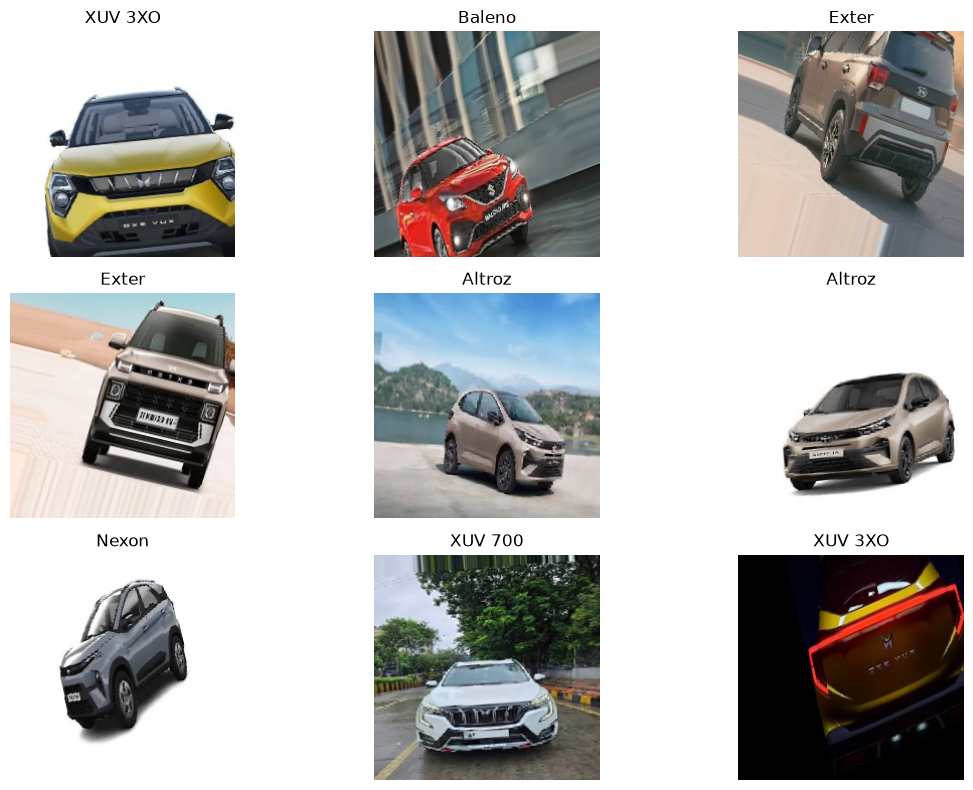

In [47]:
images, labels = next(train_generator)

print("Images in this batch:", len(images))

num_images = min(9, len(images))

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].astype("uint8"))
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

EfficientNetB0 Model

In [48]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
output = Dense(len(class_names), activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,382,647 (16.72 MB)

 Trainable params: 333,076 (1.27 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Model compilation

In [49]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


cell backs

In [50]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "best_car_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    )
]

print("Callbacks ready!")

Callbacks ready!


train the model

In [51]:
print("Total dataset:", len(df))
print("Training data:", len(train_df))
print("Validation data:", len(val_df))
print("Test data:", len(test_df))

print("\nTrain Generator:")
print("Samples:", train_generator.samples)
print("Batch size:", train_generator.batch_size)

print("\nValidation Generator:")
print("Samples:", val_generator.samples)
print("Batch size:", val_generator.batch_size)

print("\nTest Generator:")
print("Samples:", test_generator.samples)
print("Batch size:", test_generator.batch_size)

Total dataset: 1996
Training data: 1397
Validation data: 299
Test data: 300

Train Generator:
Samples: 1397
Batch size: 32

Validation Generator:
Samples: 299
Batch size: 32

Test Generator:
Samples: 300
Batch size: 32


In [52]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.1618 - loss: 2.7505 - val_accuracy: 0.3545 - val_loss: 2.2668 - learning_rate: 0.0010
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.3543 - loss: 2.1139 - val_accuracy: 0.4649 - val_loss: 1.8204 - learning_rate: 0.0010
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.4739 - loss: 1.7635 - val_accuracy: 0.5318 - val_loss: 1.5972 - learning_rate: 0.0010
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.5319 - loss: 1.5376 - val_accuracy: 0.5920 - val_loss: 1.4370 - learning_rate: 0.0010
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.5877 - loss: 1.3531 - val_accuracy: 0.5953 - val_loss: 1.3253 - learning_rate: 0.0010
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.6321 - loss: 1.2118 - val_accuracy: 0.6254 - val_loss: 1.2412 - learning_rate: 0.0010
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.6571 - loss: 1.1324 - val_accuracy:

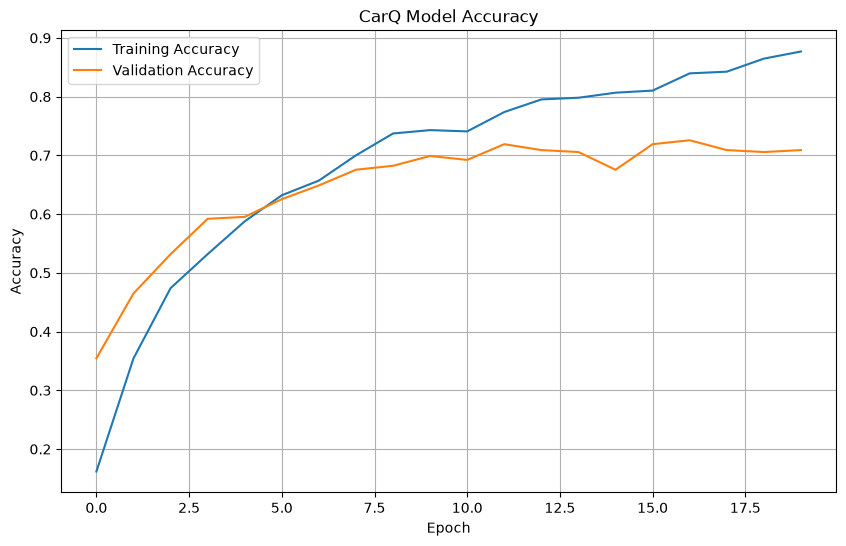

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CarQ Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

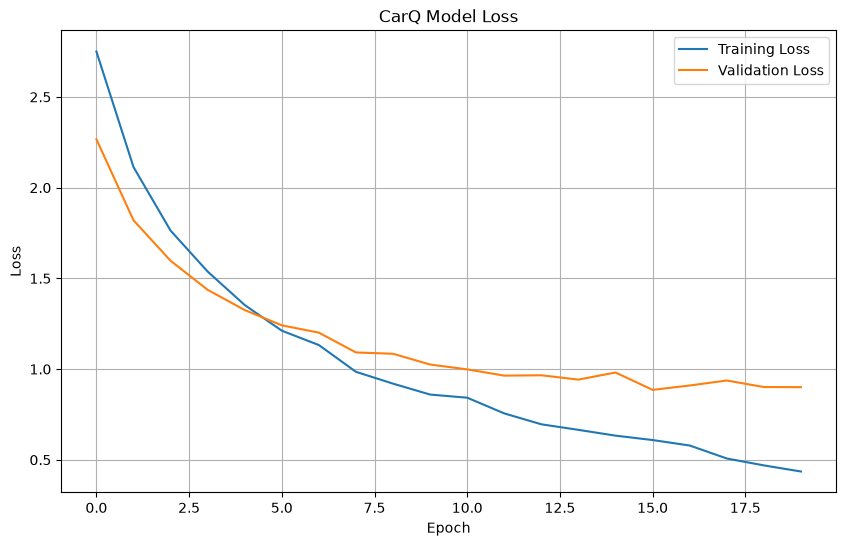

In [59]:
plt.figure(figsize=(10, 6))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CarQ Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [53]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.7033 - loss: 0.9399
Test Loss: 0.9398723244667053
Test Accuracy: 0.70333331823349
Test Accuracy (%): 70.33 %


Confusion Matrix 

10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step


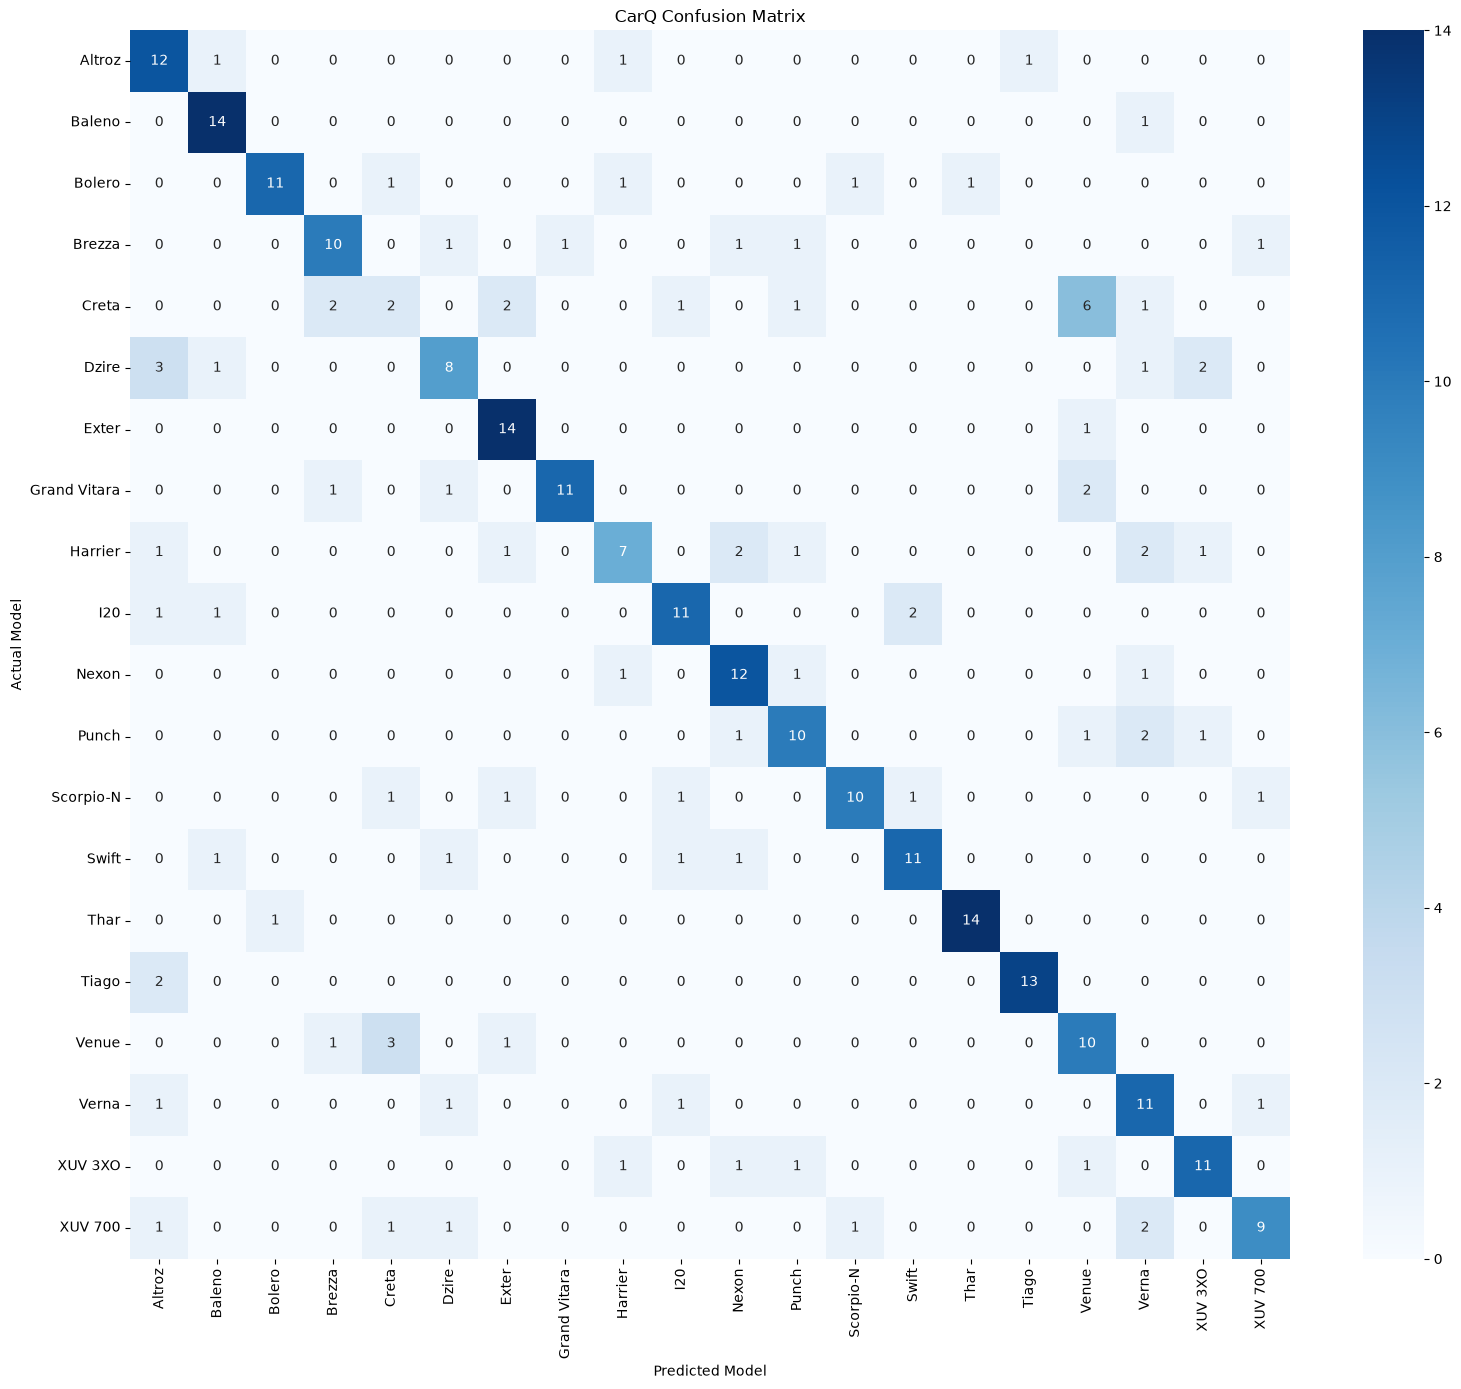

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

test_generator.reset()

predictions = model.predict(test_generator)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

cm = confusion_matrix(
    true_classes,
    predicted_classes
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CarQ Confusion Matrix")
plt.xlabel("Predicted Model")
plt.ylabel("Actual Model")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [55]:
tp = []
tn = []
fp = []
fn = []

for i in range(len(class_names)):

    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)

    tp.append(TP)
    tn.append(TN)
    fp.append(FP)
    fn.append(FN)

metrics_df = pd.DataFrame({
    "Model": class_names,
    "TP": tp,
    "TN": tn,
    "FP": fp,
    "FN": fn
})

metrics_df

,Model,TP,TN,FP,FN
0,Altroz,12,276,9,3
1,Baleno,14,281,4,1
2,Bolero,11,284,1,4
3,Brezza,10,281,4,5
4,Creta,2,279,6,13
5,Dzire,8,280,5,7
6,Exter,14,280,5,1
7,Grand Vitara,11,284,1,4
8,Harrier,7,281,4,8
9,I20,11,281,4,4


In [56]:
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df

,precision,recall,f1-score,support
Altroz,0.571429,0.800000,0.666667,15.000000
Baleno,0.777778,0.933333,0.848485,15.000000
Bolero,0.916667,0.733333,0.814815,15.000000
Brezza,0.714286,0.666667,0.689655,15.000000
Creta,0.250000,0.133333,0.173913,15.000000
Dzire,0.615385,0.533333,0.571429,15.000000
Exter,0.736842,0.933333,0.823529,15.000000
Grand Vitara,0.916667,0.733333,0.814815,15.000000
Harrier,0.636364,0.466667,0.538462,15.000000
I20,0.733333,0.733333,0.733333,15.000000


10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step


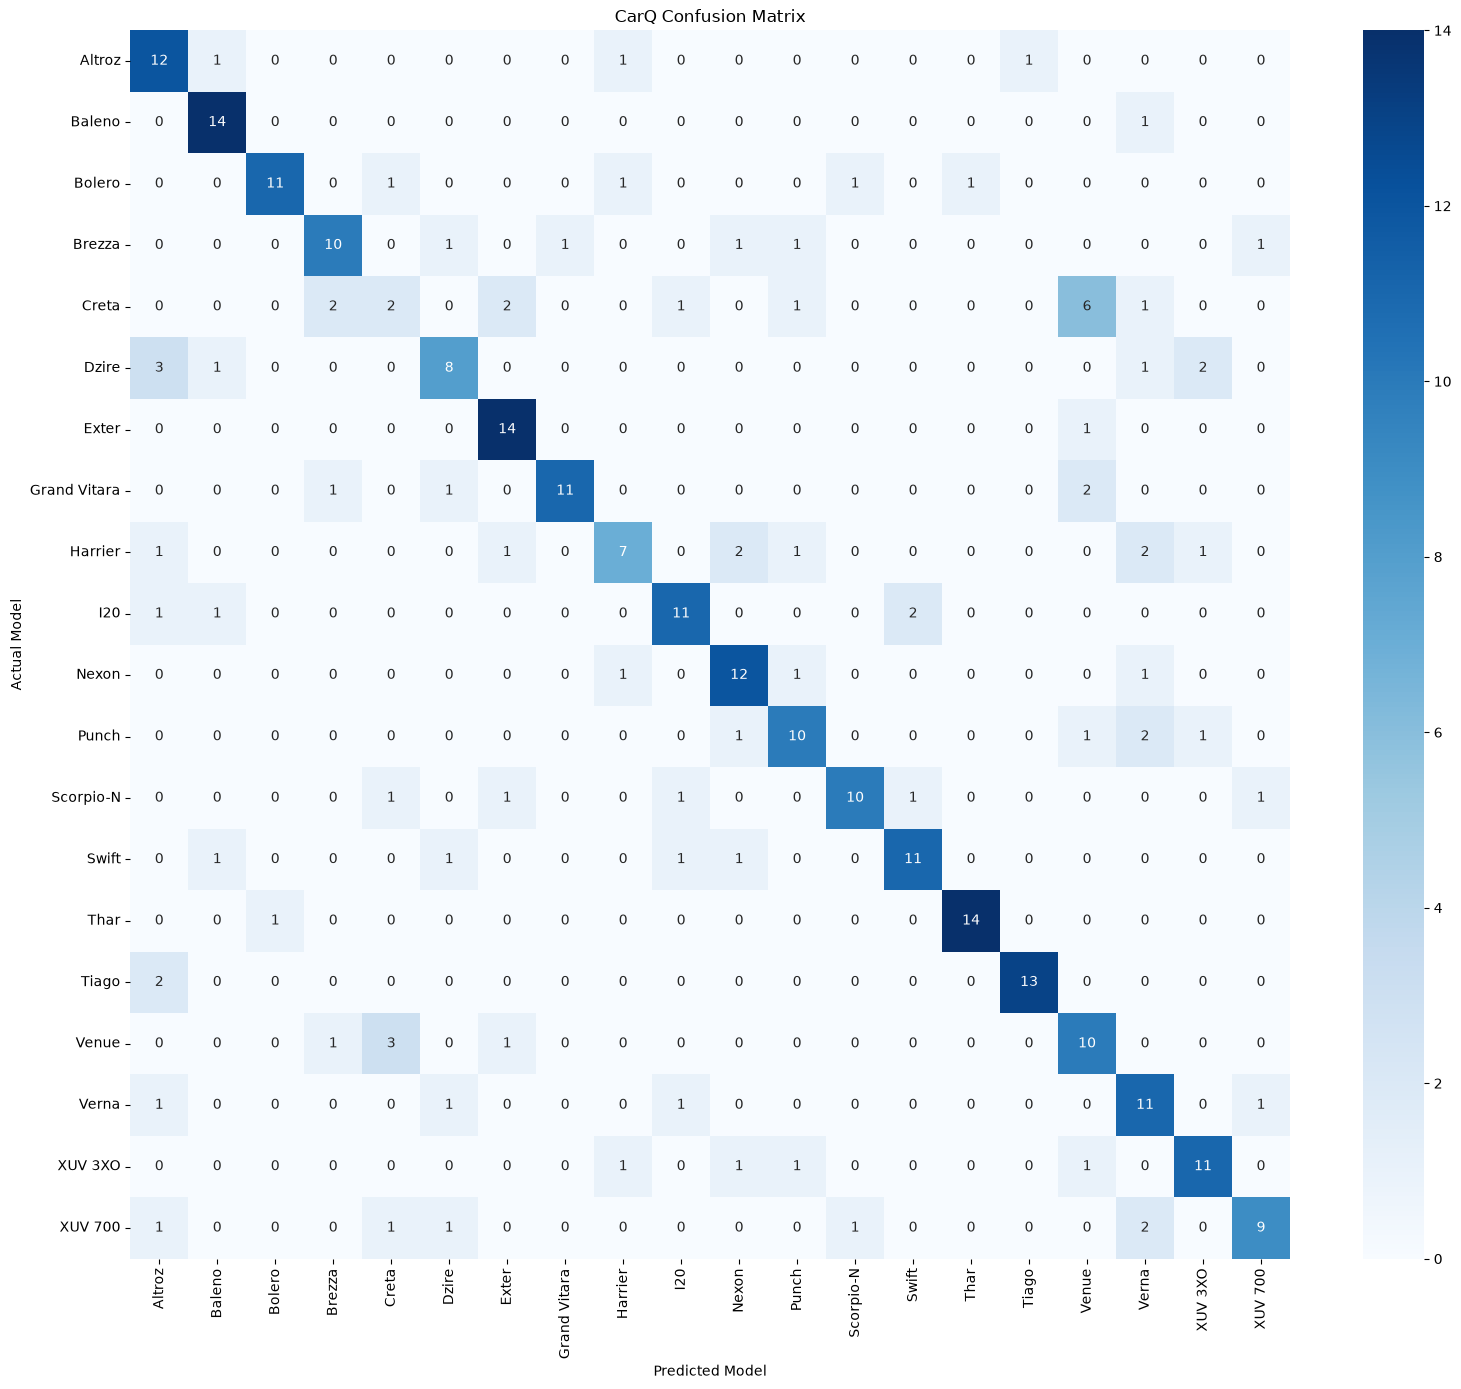

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

test_generator.reset()

predictions = model.predict(test_generator)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

class_names = list(test_generator.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CarQ Confusion Matrix")
plt.xlabel("Predicted Model")
plt.ylabel("Actual Model")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()